# Who gets the good Batman stories?

Doug Moench and Kelley Jones made *Red Rain*, the **#6** Batman story ever. They also made *Unseen*, which ranks **#716** of 740. Same writer, same artist, 710 places apart.

That list is [BatChat](https://comicsxf.com/batchat-rankings/), a podcast where **Matt Lazorwitz and Will Nevin** have read and ranked **740 Batman stories** from 1939 to today. This notebook is about the people who made them: which writers, artists, letterers, and eras keep landing near the top.

Everything here describes the books the hosts chose to cover, not whole careers. **Rank 1 is best; lower is better throughout.**

<details><summary>Three words you'll see a lot</summary>

- **Rank**: position on BatChat's list. #1 is the best Batman story; #740 the worst. Lower is better everywhere here.
- **Median rank**: the typical rank for a group. Half the group's stories rank above it, half below.
- **Selected story**: an issue can hold several stories (a lead feature and a backup). We only count the one the podcast actually ranked, and the people who made *that* one.

</details>

By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ) · [Dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings) · [Code and sources](https://github.com/ddofer/BatRank)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import HTML, display

# Kaggle mounts the dataset under /kaggle/input; locally, `make share` stages it in data/kaggle.
DATA = next(
    p.parent
    for root in ["/kaggle/input", "data/kaggle", "../data/kaggle"]
    for p in Path(root).rglob("stories.csv")
)
COLORS = {"blue": "#2767A0", "orange": "#D57927", "green": "#26806B", "grey": "#75818C"}
ROLES = ["writers", "pencilers", "inkers", "colorists", "letterers", "editors"]
sns.set_theme(
    style="ticks",
    font_scale=1.05,
    rc={"axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold"},
)
pd.set_option("display.max_colwidth", 70)


def split_set(value):
    """Split a |-separated field into a list; missing values give an empty list."""
    return [item for item in value.split("|") if item] if isinstance(value, str) else []


def rank_summary(frame, by, **extra):
    """Count, median rank, and best/worst-ranked story titles per group."""
    return (
        frame.sort_values("rank")
        .groupby(by)
        .agg(
            n=("story_id", "nunique"),
            median_rank=("rank", "median"),
            best_rank=("rank", "first"),
            best_story=("title", "first"),
            worst_rank=("rank", "last"),
            worst_story=("title", "last"),
            **extra,
        )
    )


def rank_boxes(ax, entries, key, labels, color):
    """Box of the middle half plus one faint dot per story, in the order of `labels`."""
    chart = entries[entries[key].isin(labels.index)].assign(label=lambda d: d[key].map(labels))
    common = dict(data=chart, x="rank", y="label", order=labels.tolist(), ax=ax)
    sns.stripplot(**common, color=COLORS["grey"], alpha=0.35, size=3, jitter=False, zorder=0)
    sns.boxplot(**common, color=color, whis=0, showfliers=False, width=0.45)
    ax.set(xlabel="Story rank · lower = better", ylabel="", xlim=(1, N))


PRETTY = {
    "name": "Name",
    "display_name": "Character",
    "n": "Stories",
    "stories": "Stories",
    "median_rank": "Median rank",
    "best_rank": "Best rank",
    "best_story": "Best-ranked story",
    "worst_rank": "Worst rank",
    "worst_story": "Worst-ranked story",
}


def collapsible(summary, table, note="", **to_html):
    """Show a long table inside a click-to-expand block."""
    body = table.to_html(escape=True, **to_html)
    return HTML(f"<details><summary>{summary}</summary><p>{note}</p>{body}</details>")


stories = pd.read_csv(DATA / "stories.csv")
issues = pd.read_csv(DATA / "issues.csv")
creators = pd.read_csv(DATA / "creators.csv")
credits = pd.read_csv(DATA / "story_creators.csv")
N = len(stories)

# Credits for the selected story only, not unrelated backups in the same issue.
story_credits = credits[credits.credit_scope.eq("selected_narrative")]
# Stories whose every issue has a resolved story and full creator credits.
fully_credited = stories.loc[
    stories.metadata_complete
    & stories.substory_attribution_coverage.eq(1)
    & stories.narrative_credit_issue_coverage.eq(1),
    "story_id",
]
print(f"{N:,} ranked stories · {len(issues):,} issues · snapshot {stories.snapshot_date.iloc[0]}")

740 ranked stories · 2,434 issues · snapshot 2026-10-21


## The top and bottom of the list

Each row of `stories.csv` is one ranked story. Here are both ends of the list.

In [2]:
columns = {
    "rank": "Rank",
    "title": "Story",
    "narrative_writers": "Writers",
    "narrative_pencilers": "Pencilers",
    "cover_year_start": "Year",
}
ends = pd.concat([stories.head(10), stories.tail(5)])[list(columns)].rename(columns=columns)
ends["Year"] = ends.Year.astype("Int64")
ends[["Writers", "Pencilers"]] = ends[["Writers", "Pencilers"]].apply(
    lambda col: col.str.replace("|", ", ", regex=False)
)
ends.set_index("Rank")

,Story,Writers,Pencilers,Year
Rank,,,,
1,Year One,Frank Miller,Dave Mazzucchelli,1987
2,Ego,Darwyn Cooke,Darwyn Cooke,2000
3,Cold Days,Tom King,Lee Weeks,2018
4,The Long Halloween,Jeph Loeb,Tim Sale,1996
5,The Joker,"James Tynion IV, Matthew Rosenberg","Francesco Francavilla, Giuseppe Camuncoli, Guillem March, Stefano ...",2020
6,Batman/Dracula: Red Rain OGN,Doug Moench,Kelley Jones,1992
7,Some Of These Days,Tom King,"Lee Weeks, Michael Lark",2018
8,The Dark Knight Returns,Frank Miller,Frank Miller,1986
9,The Court of Owls,Scott Snyder,Greg Capullo,2011


## Who wrote the most of them?

**Chuck Dixon leads with 34 stories**, followed by Alan Grant with 31 and Dennis O'Neil with 28. Counts use the 677 stories where the wiki lists every writer; co-written stories count for each writer.

In [3]:
creator_stories = (
    story_credits[story_credits.story_id.isin(fully_credited)]
    .merge(creators[["creator_id", "name"]], on="creator_id", validate="many_to_one")
    .merge(stories[["story_id", "title", "rank"]], on="story_id", validate="many_to_one")
)
creator_rankings = rank_summary(creator_stories, ["role", "creator_id", "name"]).reset_index()
frequent = (
    creator_rankings.query("role == 'writers'")
    .sort_values(["n", "name"], ascending=[False, True])
    .head(12)
    .iloc[::-1]
)
era = stories.dropna(subset=["cover_year_start"]).copy()
era["decade"] = (era.cover_year_start // 10 * 10).astype(int)
decades = era.decade.value_counts().sort_index()

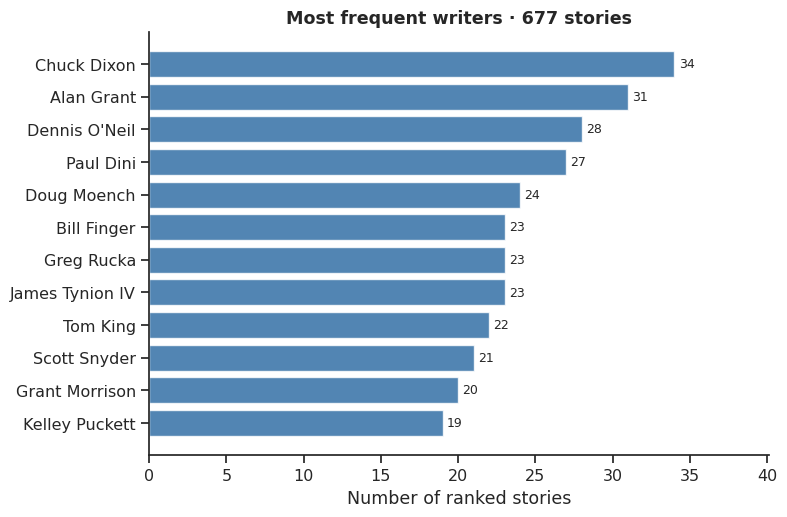

In [4]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(frequent.name, frequent.n, color=COLORS["blue"], alpha=0.8)
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
ax.set(
    xlim=(0, frequent.n.max() * 1.18),
    xlabel="Number of ranked stories",
    title=f"Most frequent writers · {creator_stories.story_id.nunique()} stories",
)
plt.show()

## The 2020s hold their own against the 1980s

**The 2020s' median rank of 300** sits right beside the **1980s' 310**, the decade of *Year One* and *The Dark Knight Returns*. Every era has favorites and disappointments. Each box shows where the middle 50% of that decade's stories land, with the median as the line inside. **Farther left is better.** The 1930s have only three stories.

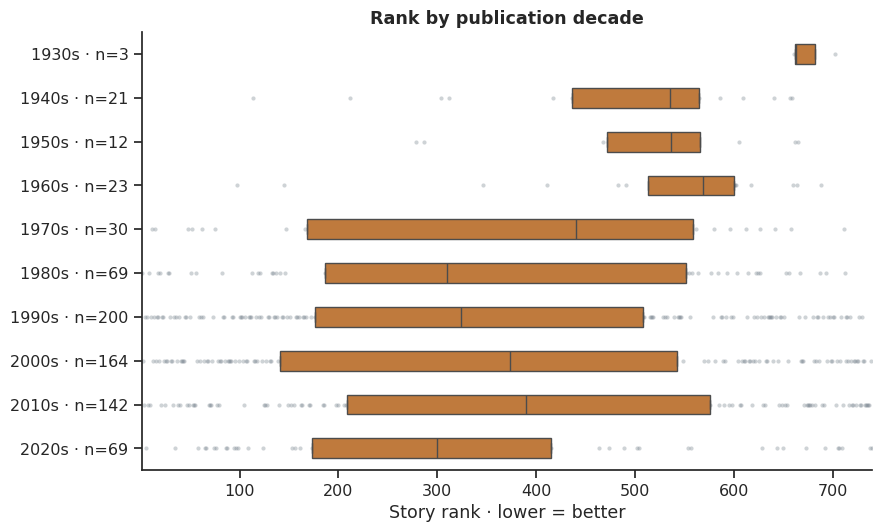

In [5]:
labels = pd.Series([f"{d}s · n={n}" for d, n in decades.items()], index=decades.index)
fig, ax = plt.subplots(figsize=(9, 5.5))
rank_boxes(ax, era, "decade", labels, COLORS["orange"])
ax.set_title("Rank by publication decade")
fig.tight_layout()
plt.show()

## The creators with the best (and worst) track records

Who has a run of favorites? Who keeps turning up near the bottom? We compare writers and pencilers separately; each needs **at least five stories with complete credits**.

Boxes show the middle half of each creator's stories, with the median inside; faint dots are individual stories. **Left is better.** A shared story counts for every contributor.

Bruce Timm leads the writers, with a median rank of **39 across five stories**. Michael Lark leads the pencilers at **40.5 across six**. Some of the best medians come from short contributions to highly ranked anthologies like *Black and White*. At the other end, J.M. DeMatteis has a median of **622 across nine stories**. Five stories is a small sample, so check the spread in the tables.

Raise the minimum to **ten stories** and the leaders become **Ed Brubaker** for writing and **Tim Sale** for pencils.

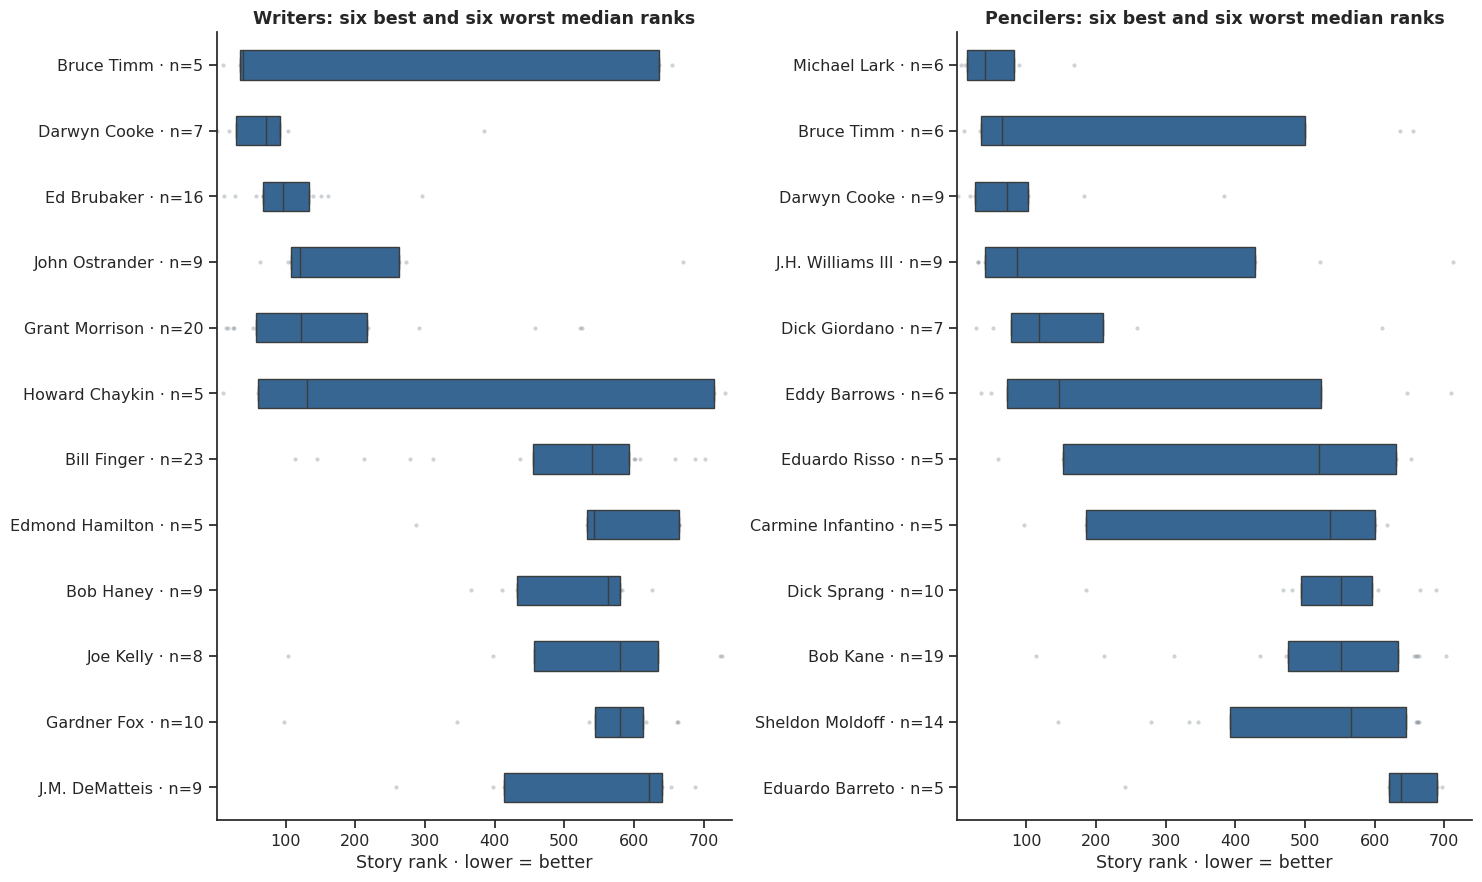

Every role, for the curious (click to expand):


Name,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Bruce Timm,5,39.0,10,Batman: Black and White Vol.1,655,Batman: Harley & Ivy #1-3
Darwyn Cooke,7,72.0,2,Ego,384,Justice League: The New Frontier Special
Ed Brubaker,16,96.5,12,Soft Targets,296,Fearless
John Ostrander,9,121.0,63,A Savage Innocence,670,Grotesk
Grant Morrison,20,121.5,15,Batman: R.I.P.,526,The Three Ghosts of Batman
Howard Chaykin,5,130.0,10,Batman: Black and White Vol.1,730,Batman: Dark Allegiances
Matt Wagner,6,155.5,10,Batman: Black and White Vol.1,469,Faces
Jeph Loeb,13,173.0,4,The Long Halloween,615,Lord of the Ring
Greg Rucka,23,194.0,12,Soft Targets,615,Lord of the Ring
Jeff Parker,9,211.0,126,Batman ’66 V.1,326,Batman/Santa Claus: Silent Knight #1-4


Name,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Michael Lark,6,40.5,7,Some Of These Days,168,Batman: Nine Lives OGN
Bruce Timm,6,65.5,10,Batman: Black and White Vol.1,655,Batman: Harley & Ivy #1-3
Darwyn Cooke,9,72.0,2,Ego,384,Justice League: The New Frontier Special
J.H. Williams III,9,87.0,30,Six Fingers,713,Chasing Clay
Dick Giordano,7,118.0,28,To Kill a Legend,610,Batman: Hollywood Knights #1-3
Eddy Barrows,6,147.5,35,Cheer,710,Grounded
John Romita Jr.,5,153.0,33,The Dark Knight Returns: The Last Crusade,728,Superman: Year One #3
Matt Wagner,6,155.5,10,Batman: Black and White Vol.1,469,Faces
Lee Garbett,5,161.0,26,Final Crisis,219,Batgirl Rising- Point of New Origin
Álvaro Martínez Bueno,6,169.5,49,Rise of the Batmen,480,Batman & Robin Eternal #1-26


Name,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Michael Lark,6,40.5,7,Some Of These Days,168,Batman: Nine Lives OGN
Darwyn Cooke,7,72.0,2,Ego,384,Justice League: The New Frontier Special
J.H. Williams III,6,75.5,31,Beautiful People,522,The Club of Heroes
Bruce Timm,7,92.0,10,Batman: Black and White Vol.1,655,Batman: Harley & Ivy #1-3
Klaus Janson,6,120.0,8,The Dark Knight Returns,193,DC Pride 2021
Norm Breyfogle,9,120.0,22,Knightfall Part 1: The Broken Bat,481,Ecstasy
Drew Geraci,5,122.0,26,Final Crisis,314,I was the Love Slave of a Planet Based Killer
Eber Ferreira,5,140.0,35,Cheer,646,Perpetual Motion
Raúl Fernández,6,169.5,49,Rise of the Batmen,480,Batman & Robin Eternal #1-26
Tim Sale,11,173.0,4,The Long Halloween,703,The Wedding


Name,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Tatjana Wood,5,119.0,20,The Garden of Earthly Delights,222,Riddles
Nathan Fairbairn,6,129.0,25,Leviathan Strikes,355,Superheavy
Adriano Lucas,7,140.0,35,Cheer,369,New Year’s Evil V.2 #1
Matt Hollingsworth,13,168.0,24,Half a Life,737,Batman: Curse of the White Knight #1-8
Tony Aviña,11,170.0,26,Final Crisis,675,Golden Dawn
Marissa Louise,5,193.0,65,Sword of Azrael (2022) #1-6,557,"Harley Quinn: The Animated Series- The Eat, Bang, Kill Tour #1-6"
James Sinclair,6,201.0,44,Blink,549,Terror
Dave Stewart,28,237.0,19,The New Frontier,630,A Grim Knight in Gotham
José Villarrubia,6,245.0,53,Batman: The Return of Bruce Wayne #1-6,703,The Wedding
Romulo Fajardo Jr.,5,250.0,184,Batman: Eternal V.3,590,The Princess and the Knight


Name,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Kurt Hathaway,5,107.0,44,Blink,549,Terror
Sean Konot,7,132.0,27,Anodyne,704,The Fishy Laugh
Ariana Maher,5,193.0,86,DC Pride 2022,392,Gotham Villains 80th Anniversary Giant
Clem Robins,17,194.0,12,Soft Targets,731,The Surrogate
Tom Napolitano,16,223.0,87,Batman: Black and White V.4,717,Fear of the Dark
Richard Starkings,28,231.0,4,The Long Halloween,718,"Batman: The Blue, The Grey, and the Bat"
John Workman,17,235.0,10,Batman: Black and White Vol.1,728,Superman: Year One #3
Todd Klein,70,251.0,1,Year One,734,Batman: White Knight #1-8
Troy Peteri,13,254.0,40,Father’s Day,709,Tales from the Dark Multiverse: Batman- Hush
Willie Schubert,36,287.5,24,Half a Life,697,Knightquest: The Search


Name,Stories,Median rank,Best rank,Best-ranked story,Worst rank,Worst-ranked story
Mark Chiarello,12,66.0,2,Ego,585,Batman: Noel OGN
E. Nelson Bridwell,7,147.0,14,Strange Apparitions,711,The Last Batman Story–?
Matt Idelson,20,172.0,12,Soft Targets,710,Grounded
Nachie Castro,19,194.0,12,Soft Targets,714,Brothers in Blood
Aniz Ansari,9,223.0,38,Batman ’66: The Lost Episode,409,Injustice: Gods Among Us Vol.2
Michael McCalister,5,224.0,86,DC Pride 2022,271,Hammer of Justice
Chuck Kim,12,231.5,4,The Long Halloween,540,Werewolf
Rob Levin,6,249.5,69,Everyday.,676,Manslaughter
Dan Raspler,27,255.0,29,Batman: The Cult #1-4,629,Robin Lives!
Jim Chadwick,24,262.0,38,Batman ’66: The Lost Episode,674,Injustice: Gods Among Us Year 4 Vol. 2


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 9), sharex=True)
for ax, role in zip(axes, ["writers", "pencilers"]):
    eligible = creator_rankings.query("role == @role and n >= 5").sort_values("median_rank")
    extremes = pd.concat([eligible.head(6), eligible.tail(6)]).set_index("creator_id")
    labels = extremes.name + " · n=" + extremes.n.astype(str)
    rank_boxes(
        ax, creator_stories[creator_stories.role.eq(role)], "creator_id", labels, COLORS["blue"]
    )
    ax.set_title(f"{role.capitalize()}: six best and six worst median ranks")
fig.tight_layout()
plt.show()

print("Every role, for the curious (click to expand):")
shown_columns = list(PRETTY)[:1] + list(PRETTY)[2:3] + list(PRETTY)[4:]
for role in ROLES:
    table = creator_rankings.query("role == @role and n >= 5").sort_values("median_rank")
    display(
        collapsible(
            f"{role.capitalize()}: all {len(table)} names with five or more stories",
            table[shown_columns].rename(columns=PRETTY),
            "Median rank: lower is better. Best and worst examples show the range.",
            index=False,
        )
    )

## Do younger writers fare worse?

Stories by writers under 30 have a median rank of **484**, which suggests older writers do better. Then we split the group by decade:

- **1940s:** ten stories, median **543**.
- **1980s:** ten stories, median **141.5**.

Same age bracket, very different Batman comics. Read across a row to compare ages, or down a column to follow one age group through the decades. **Darker blue means better ranked.** Grey cells have fewer than five stories.

<details><summary>Calculating writer ages</summary>

The 512 included stories have complete issue lists and known ages for every writer. Writer's age = issue year minus birth year; co-written stories use the median age. These are approximate ages, not birthdays matched to publication dates.

</details>

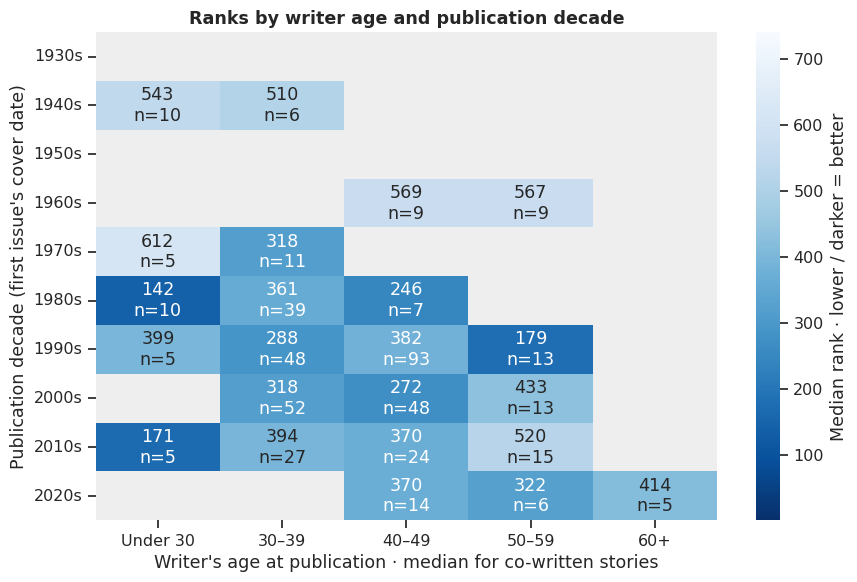

In [7]:
writer_age = (
    story_credits[story_credits.role.eq("writers")]
    .groupby("story_id")
    .agg(
        writers=("creator_id", "size"),
        known_ages=("age_at_publication_year_proxy", "count"),
        age=("age_at_publication_year_proxy", "median"),
    )
    .query("writers == known_ages")
    .merge(
        stories[
            [
                "story_id",
                "rank",
                "cover_year_start",
                "metadata_complete",
                "narrative_credit_issue_coverage",
            ]
        ],
        on="story_id",
        validate="one_to_one",
    )
)
writer_age = writer_age[
    writer_age.metadata_complete & writer_age.narrative_credit_issue_coverage.eq(1)
]
writer_age["age_band"] = pd.cut(
    writer_age.age, [-1, 29, 39, 49, 59, 110], labels=["Under 30", "30–39", "40–49", "50–59", "60+"]
)
writer_age["decade"] = (writer_age.cover_year_start // 10 * 10).astype(int)
age_profile = writer_age.groupby(["decade", "age_band"], observed=True)["rank"].agg(
    n="size", median="median"
)
medians = age_profile["median"].unstack("age_band")
counts = age_profile.n.unstack("age_band")

fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(
    medians.where(counts.ge(5)),
    annot=medians.round().astype("Int64").astype(str) + "\nn=" + counts.astype("Int64").astype(str),
    fmt="",
    mask=counts.lt(5),
    vmin=1,
    vmax=N,
    cmap="Blues_r",
    ax=ax,
    yticklabels=[f"{year}s" for year in medians.index],
    cbar_kws={"label": "Median rank · lower / darker = better"},
)
ax.set_facecolor("#EEEEEE")
ax.set(
    xlabel="Writer's age at publication · median for co-written stories",
    ylabel="Publication decade (first issue's cover date)",
    title="Ranks by writer age and publication decade",
)
fig.tight_layout()
plt.show()

Writer age and publication era are tangled together here, and the sparse cells show how little evidence there is for comparing ages within some decades.

## Same writer, different comic

Back to the pair from the intro: *Red Rain* (**#6**) and *Unseen* (**#716**), both by **Doug Moench and Kelley Jones**.

The chart compares four writer–artist partnerships. Each dot is a story; each bar is a median. Even with both names fixed, there is plenty of room for a hit or a miss.

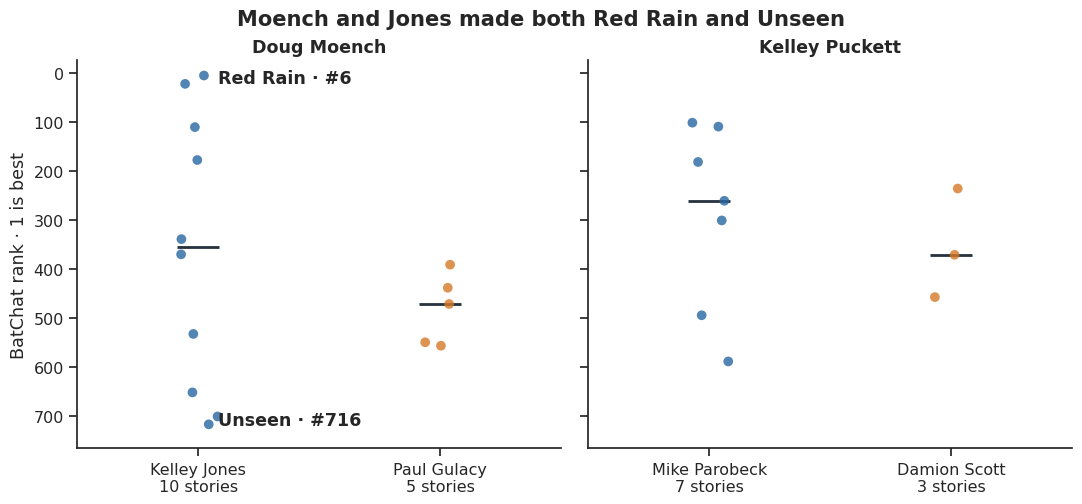

In [8]:
single_team = stories[
    stories.narrative_writers.notna()
    & ~stories.narrative_writers.str.contains("|", regex=False, na=False)
    & stories.narrative_pencilers.notna()
    & ~stories.narrative_pencilers.str.contains("|", regex=False, na=False)
    & stories.narrative_credit_issue_coverage.eq(1)
]
pairs = {
    "Doug Moench": ["Kelley Jones", "Paul Gulacy"],
    "Kelley Puckett": ["Mike Parobeck", "Damion Scott"],
}
teamed = single_team[
    [
        p in pairs.get(w, [])
        for w, p in zip(single_team.narrative_writers, single_team.narrative_pencilers)
    ]
].rename(columns={"narrative_writers": "Writer", "narrative_pencilers": "Penciler"})
g = sns.catplot(
    data=teamed,
    x="Penciler",
    y="rank",
    col="Writer",
    hue="Penciler",
    kind="strip",
    sharex=False,
    jitter=0.08,
    size=7,
    alpha=0.8,
    legend=False,
    palette={
        a: [COLORS["blue"], COLORS["orange"]][i]
        for arts in pairs.values()
        for i, a in enumerate(arts)
    },
    height=5,
    aspect=1.1,
)
g.map_dataframe(
    sns.pointplot, x="Penciler", y="rank", estimator="median", errorbar=None,
    linestyle="none", markers="_", markersize=30, color="#273440",
)  # fmt: skip
g.set(ylim=(N + 25, -25)).set_axis_labels("", "BatChat rank · 1 is best").set_titles("{col_name}")
for ax, writer in zip(g.axes.flat, pairs):
    counts = teamed[teamed.Writer.eq(writer)].Penciler.value_counts()
    ax.set_xticks(range(len(pairs[writer])), [f"{a}\n{counts[a]} stories" for a in pairs[writer]])
for title, rank, dy in [("Red Rain · #6", 6, -2), ("Unseen · #716", 716, 3)]:
    g.axes.flat[0].annotate(
        title,
        (0, rank),
        xytext=(14, dy),
        textcoords="offset points",
        va="center",
        fontweight="bold",
    )
g.figure.suptitle("Moench and Jones made both Red Rain and Unseen", y=1.02, fontweight="bold")
plt.show()

Kelley Puckett's books with Mike Parobeck have a median rank of **261 across seven stories**. With Damion Scott, it's **371 across three**.

But Parobeck's books belong to the world of *Batman: The Animated Series*, while Scott's include Cassandra Cain's early *Batgirl* stories and her introduction in *No Man's Land*. The artist, the protagonist, and the kind of comic all change together, so calling the difference "artist quality" would miss the point. [DC on Batman Adventures](https://www.dc.com/graphic-novels/batman-adventures-1992/batman-adventures-vol-2) · [DC on Scott and Cassandra Cain](https://www.dc.com/blog/2023/02/23/power-on-page-six-dc-comics-by-black-creators)

### Does keeping one team help an arc?

An artist change halfway through a story can be jarring. Arcs with the same writers and pencilers throughout have a median rank of **316.5**, versus **340** for arcs whose team changes.

Longer arcs have more chances to change artists, so we split by length. Stable teams rank about **30 places better at 3–4 issues**, **5 better at 5–6**, and **6 worse at 7+**. The dots tell the bigger story: both groups span most of the ranking. Black bars show medians.

<details><summary>Which arcs qualify?</summary>

At least three issues, a complete issue list, and known writers and pencilers throughout. "One team" means the same set of those people in every issue.

</details>

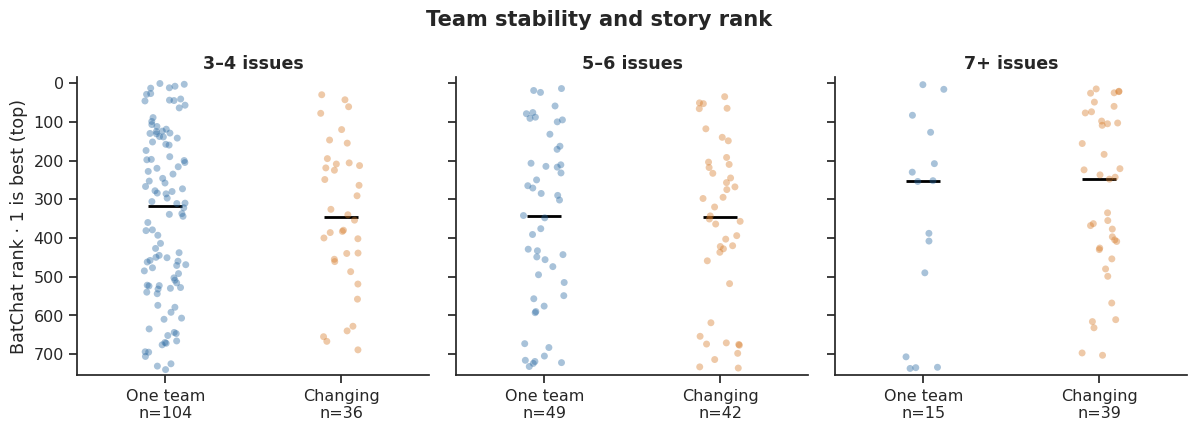

In [9]:
multi_story_issues = issues.selected_substory_indexes.fillna("").str.contains(
    "|", regex=False, na=False
)
teams = stories[
    stories.issue_count.ge(3)
    & ~stories.story_id.isin(issues.loc[multi_story_issues, "story_id"])
    & stories.metadata_complete
    & stories.narrative_credit_issue_coverage.eq(1)
].copy()
teams["stable_team"] = teams.narrative_dominant_team_share.eq(1)
teams["length_band"] = pd.cut(
    teams.issue_count, [2, 4, 6, np.inf], labels=["3–4 issues", "5–6 issues", "7+ issues"]
)
team_counts = teams.groupby(["length_band", "stable_team"], observed=True).size()

np.random.seed(42)  # fixes the strip-plot jitter
g = sns.catplot(
    data=teams,
    x="stable_team",
    y="rank",
    col="length_band",
    order=[True, False],
    hue="stable_team",
    legend=False,
    palette={True: COLORS["blue"], False: COLORS["orange"]},
    kind="strip",
    sharex=False,
    jitter=0.12,
    alpha=0.4,
    height=4.5,
    aspect=0.9,
)
g.map_dataframe(
    sns.pointplot,
    x="stable_team",
    y="rank",
    order=[True, False],
    estimator="median",
    errorbar=None,
    markers="_",
    linestyles="none",
    color="black",
    markersize=24,
)
g.set(ylim=(N + 15, -15)).set_axis_labels("", "BatChat rank · 1 is best (top)").set_titles(
    "{col_name}"
)
for ax, band in zip(g.axes.flat, teams.length_band.cat.categories):
    n = team_counts.loc[band].reindex([True, False])
    ax.set_xticks([0, 1], [f"One team\nn={n[True]}", f"Changing\nn={n[False]}"])
g.figure.subplots_adjust(top=0.82)
g.figure.suptitle("Team stability and story rank", y=0.97, fontweight="bold")
plt.show()

### The names that recur across runs

John Costanza and Todd Klein lead the lettering credits, and Adrienne Roy leads color. These names connect books that fans usually discuss by writer or penciler.

Across the same **589 stories**, five letterers did **34.6%** of all the lettering. The five busiest writers did **18.3%** of the writing, and the five busiest pencilers only **9.5%**.

<details><summary>Counting shared assignments</summary>

Each story contributes one unit per role, split equally among its contributors; two writers get half each. All 589 stories have all six roles recorded. Studios are included. #
</details>

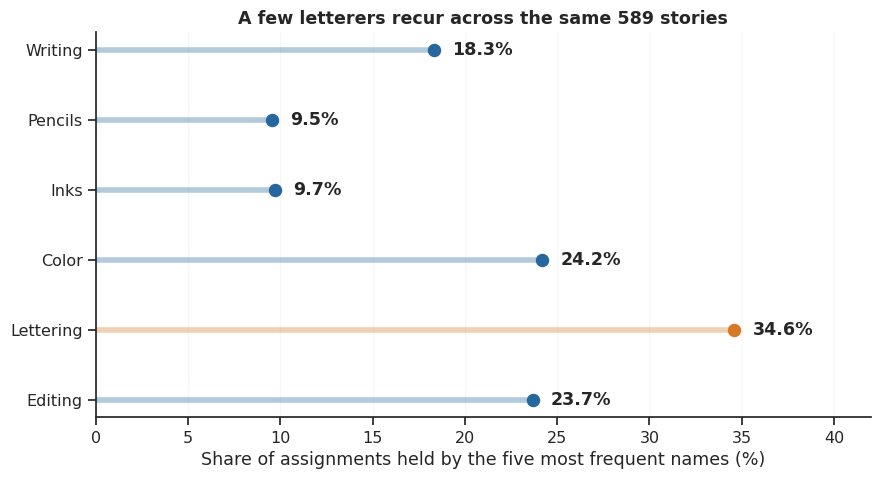

In [10]:
role_links = story_credits[story_credits.story_id.isin(fully_credited)].copy()
role_links = role_links.groupby("story_id").filter(lambda g: g.role.nunique() == len(ROLES))
role_links["credit_share"] = 1 / role_links.groupby(["story_id", "role"]).creator_id.transform(
    "size"
)
n_complete = role_links.story_id.nunique()
credit_counts = (
    role_links.groupby(["role", "creator_id"])
    .agg(readings=("story_id", "nunique"), share=("credit_share", "sum"))
    .reset_index()
    .merge(creators[["creator_id", "name"]], on="creator_id", validate="many_to_one")
    .assign(share=lambda d: d.share / n_complete)
    .sort_values("share", ascending=False)
)
top_five_share = credit_counts.groupby("role").head(5).groupby("role").share.sum().reindex(ROLES)
role_labels = {
    "writers": "Writing",
    "pencilers": "Pencils",
    "inkers": "Inks",
    "colorists": "Color",
    "letterers": "Lettering",
    "editors": "Editing",
}
fig, ax = plt.subplots(figsize=(10, 5))
for pos, (role, share) in enumerate(top_five_share.items()):
    color = COLORS["orange"] if role == "letterers" else COLORS["blue"]
    ax.hlines(pos, 0, 100 * share, color=color, lw=4, alpha=0.35)
    ax.scatter(100 * share, pos, s=75, color=color, zorder=3)
    ax.text(100 * share + 1, pos, f"{100 * share:.1f}%", va="center", fontweight="bold")
ax.set(
    yticks=range(len(ROLES)),
    yticklabels=[role_labels[r] for r in ROLES],
    xlim=(0, 42),
    xlabel="Share of assignments held by the five most frequent names (%)",
    title=f"A few letterers recur across the same {n_complete} stories",
)
ax.invert_yaxis()
ax.xaxis.grid(True, alpha=0.15)
plt.show()

Two busiest names per role. These connect books that fans usually discuss by writer or penciler.

In [11]:
top_names = credit_counts.groupby("role").head(2)
display(
    top_names.assign(Role=top_names.role.map(role_labels))
    .rename(columns={"name": "Name", "readings": "Stories"})[["Role", "Name", "Stories"]]
    .set_index("Role")
    .loc[list(role_labels.values())]
)

,Name,Stories
Role,,
Writing,Chuck Dixon,33
Writing,Alan Grant,30
Pencils,Kelley Jones,15
Pencils,Norm Breyfogle,17
Inks,Rick Burchett,17
Inks,Steve Mitchell,14
Color,Adrienne Roy,66
Color,Dave Stewart,27
Lettering,John Costanza,69


## Three comparisons worth reading

- **Red Rain and Unseen:** the same writer and artist, 710 places apart.
- **The 2020s and the 1980s:** medians of 300 and 310. Modern Batman holds up.
- **Todd Klein:** 70 stories lettered, from #1 (*Year One*) to #734.

**More BatChat notebooks:** [Gotham's rogues, ranked](https://www.kaggle.com/code/danofer/gotham-s-rogues-ranked) · [What Batman plots are made of](https://www.kaggle.com/code/danofer/what-batman-plots-are-made-of) · [Can a computer predict BatChat's favorites?](https://www.kaggle.com/code/danofer/batchat-s-favorite-batman-stories) · [BatChat vs the crowd](https://www.kaggle.com/code/danofer/batchat-vs-the-crowd-where-batman-fans-disagree) · [The dataset](https://www.kaggle.com/datasets/danofer/batchat-batman-rankings)
#
# If you enjoyed this, an upvote helps other Batman fans find it.